# Assignment 3: Exploratory Data Analysis (EDA)
### Titanic Case Study, following Lecture 06 (EDA Case Study Approach)

**Dataset:** Titanic: Machine Learning from Disaster (Kaggle)  
**Link:** https://www.kaggle.com/competitions/titanic/data  
**Problem:** Why do some passengers survive and others do not?  
**Target variable:** `Survived` (0 = No, 1 = Yes)  
**Example question:** *Can passenger class, sex and fare help explain survival?*

**Lecture flow followed:** Cleaning → Dataset → Target → Histogram → Density → Bar chart → Boxplot → Feature vs Target → Scatter → Heatmap → Multivariate → Trends & Anomalies → Modeling decisions.

## Data Cleaning & Preprocessing
*Cleaning makes data correct. Preprocessing makes data ready. EDA makes data understandable.*

Cleaning steps: missing `Age` filled with the median of each Title + Pclass group, missing `Embarked` filled with the most common port, `Cabin` converted to a `HasCabin` flag and then dropped.  
Preprocessing steps: new features `Title`, `FamilySize`, `LogFare`; identifier columns removed.

In [ ]:
import glob
print(glob.glob("/kaggle/input/**/*.csv", recursive=True))

In [93]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Kaggle input folder mein train.csv khud dhoondo
files = glob.glob("/kaggle/input/**/train.csv", recursive=True)
if not files:
    raise FileNotFoundError("train.csv nahi mili. Right side se '+ Add Input' karke Titanic dataset add karein.")
path = files[0]
print("Loading from:", path)

df_raw = pd.read_csv(path)     # original copy
df = df_raw.copy()             # cleaned copy

# --- Cleaning ---
df["Title"] = df["Name"].str.extract(r", (\w+)\.")
df["Title"] = df["Title"].replace(["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
rare = df["Title"].value_counts()[lambda s: s < 10].index
df["Title"] = df["Title"].replace(rare, "Rare")
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Age"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# --- Preprocessing (new features) ---
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["LogFare"] = np.log1p(df["Fare"])
df["Survival"] = df["Survived"].map({0: "No", 1: "Yes"})
df = df.drop(columns=["PassengerId", "Ticket", "Cabin"])

print("Shape:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())

Loading from: /kaggle/input/competitions/titanic/train.csv
Shape: (891, 14)
Missing values after cleaning: 1


## Step 1: Understand the Dataset

In [94]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("Numerical  :", ["Age", "Fare", "SibSp", "Parch", "FamilySize"])
print("Categorical:", ["Sex", "Pclass", "Embarked", "Title", "Survived (target)"])
display(df.head(6))
display(df.describe().round(2))

Rows: 891 | Columns: 14
Numerical  : ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize']
Categorical: ['Sex', 'Pclass', 'Embarked', 'Title', 'Survived (target)']


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title,HasCabin,FamilySize,LogFare,Survival
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Mr,0,2,2.110213,No
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,Mrs,1,2,4.280593,Yes
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Miss,0,1,2.188856,Yes
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Mrs,1,2,3.990834,Yes
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Mr,0,1,2.202765,No
5,0,3,"Moran, Mr. James",male,26.0,0,0,8.4583,Q,Mr,0,1,2.246893,No


,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,FamilySize,LogFare
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.14,0.52,0.38,32.20,0.23,1.90,2.96
std,0.49,0.84,13.49,1.10,0.81,49.69,0.42,1.61,0.97
min,0.00,1.00,0.42,0.00,0.00,0.00,0.00,1.00,0.00
25%,0.00,2.00,21.00,0.00,0.00,7.91,0.00,1.00,2.19
50%,0.00,3.00,26.00,0.00,0.00,14.45,0.00,1.00,2.74
75%,1.00,3.00,36.75,1.00,0.00,31.00,0.00,2.00,3.47
max,1.00,3.00,80.00,8.00,6.00,512.33,1.00,11.00,6.24


**Interpretation.** 891 passengers (rows) and 14 columns after cleaning. Each row is one passenger. Numerical features: Age, Fare, SibSp, Parch, FamilySize. Categorical features: Sex, Pclass, Embarked, Title. The target is `Survived`. Originally `Age` had 177 and `Embarked` 2 missing values; `Age` was filled using the median of each Title + Pclass group, `Embarked` with its most common port.

## Step 2: Explore the Target Variable

Survival
No     549
Yes    342
Name: count, dtype: int64 

Survival
No     61.6 %
Yes    38.4 %
Name: count, dtype: object
Imbalance ratio: 1.61


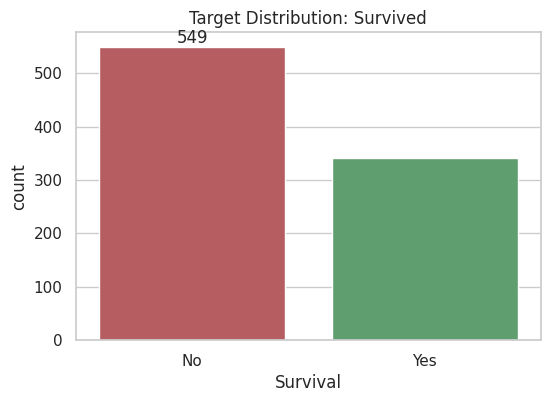

In [95]:
counts = df["Survival"].value_counts()
print(counts, "\n")
print((counts / len(df) * 100).round(1).astype(str) + " %")
print("Imbalance ratio:", round(counts.max() / counts.min(), 2))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Survival", order=["No", "Yes"], palette=["#c44e52", "#55a868"])
ax.bar_label(ax.containers[0])
plt.title("Target Distribution: Survived"); plt.show()

**Interpretation.** 549 passengers (61.6%) did not survive and 342 (38.4%) did. The "Yes" class is smaller, so the dataset is **somewhat imbalanced** (ratio 1.6 : 1), which is not severe. A model that always predicts "No" would already get 61.6% accuracy, so evaluation should not rely on accuracy alone.

## Step 3: One Numerical Feature, Histogram

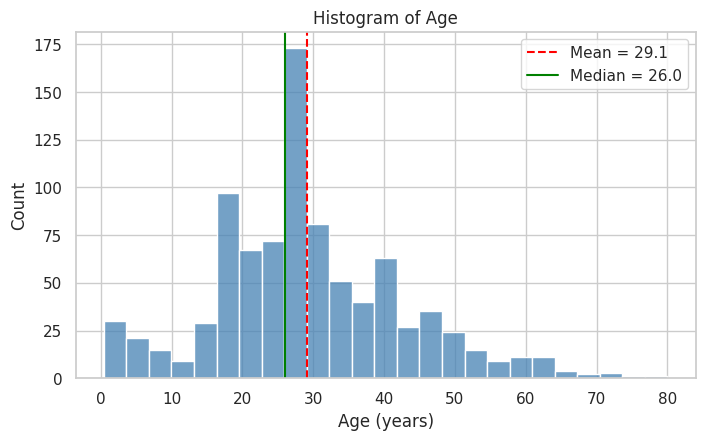

In [96]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df["Age"], bins=25, color="steelblue")
plt.axvline(df["Age"].mean(), color="red", ls="--", label=f"Mean = {df['Age'].mean():.1f}")
plt.axvline(df["Age"].median(), color="green", label=f"Median = {df['Age'].median():.1f}")
plt.title("Histogram of Age"); plt.xlabel("Age (years)"); plt.legend(); plt.show()

**Interpretation.** Most passengers are young adults: the middle 50% lie between about 21 and 37 years. There is a small extra bar of infants and children (under 5) and a thin tail towards 80. The shape is slightly right-skewed (skew 0.47), with mean 29.1 above median 26.

## Step 4: One Numerical Feature, Density Plot

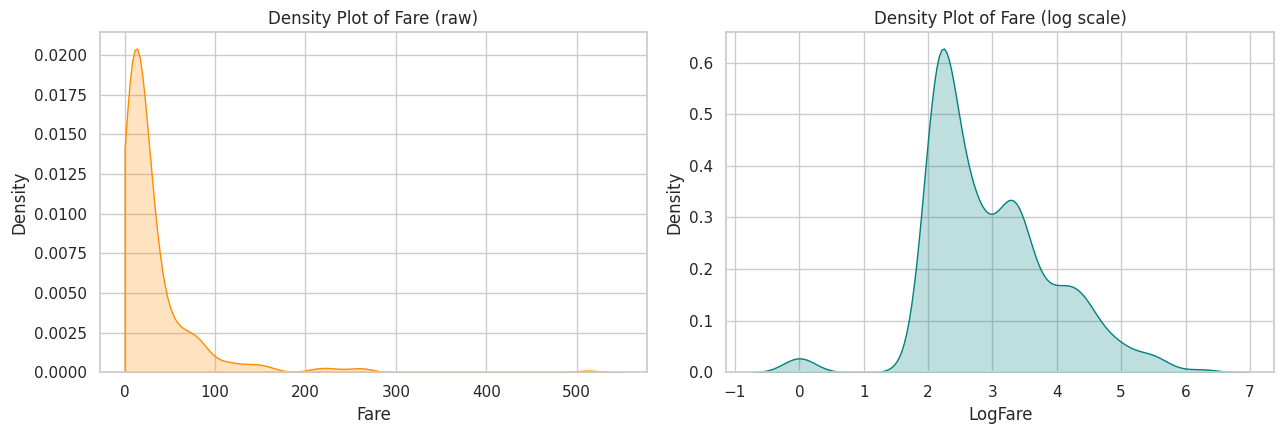

Skewness  Fare: 4.79 | LogFare: 0.39


In [97]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.kdeplot(df["Fare"], fill=True, color="darkorange", ax=axes[0], clip=(0, None))
axes[0].set_title("Density Plot of Fare (raw)")
sns.kdeplot(df["LogFare"], fill=True, color="teal", ax=axes[1])
axes[1].set_title("Density Plot of Fare (log scale)")
plt.tight_layout(); plt.show()
print("Skewness  Fare:", round(df["Fare"].skew(), 2), "| LogFare:", round(df["LogFare"].skew(), 2))

**Interpretation.** The raw Fare density has one sharp peak near 7 to 15 and a long right tail up to 512 (skew 4.8). Most tickets are cheap and a few are very expensive. After the log transform the shape is much more balanced, so `LogFare` is better for models.

## Step 5: One Categorical Feature, Bar Chart

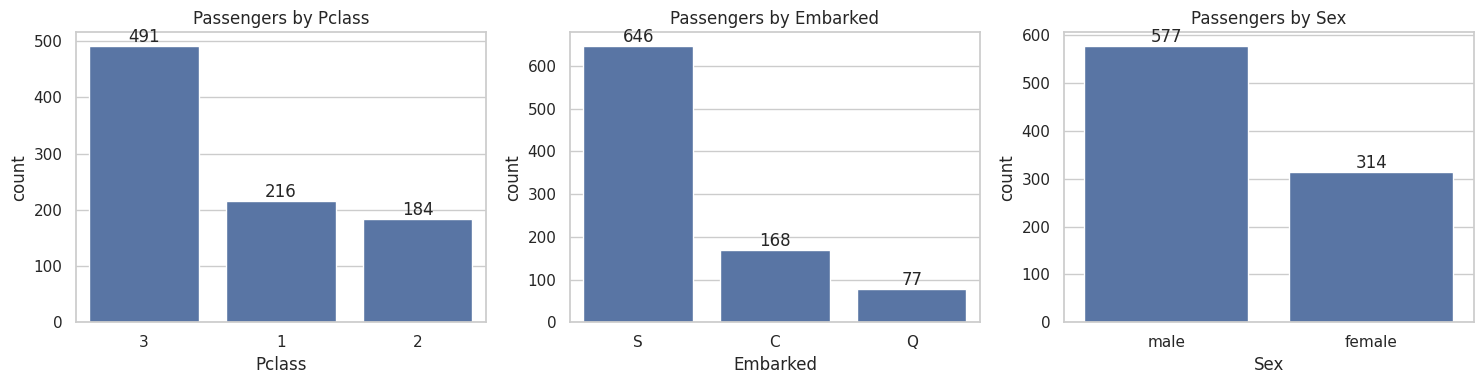

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Pclass", "Embarked", "Sex"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.bar_label(ax.containers[0]); ax.set_title(f"Passengers by {col}")
plt.tight_layout(); plt.show()

**Interpretation.** Class 3 is the biggest group (491 passengers), then class 1 (216) and class 2 (184). Southampton (S) is the main boarding port (646), far ahead of Cherbourg (168) and Queenstown (77). Males (577) outnumber females (314). Category sizes are clearly unequal, so rates must be read with group counts.

## Step 6: Spread and Outliers, Boxplot

In [ ]:
def labeled_boxplot(col, ax, color):
    sns.boxplot(x=df[col], ax=ax, color=color)
    q1, med, q3 = df[col].quantile([.25, .5, .75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    ax.set_ylim(1.1, -0.5)   # box ke neeche labels ke liye jagah
    for v, name, y, ha in [(q1, "Q1", 0.65, "right"), (med, "Median", 0.95, "center"), (q3, "Q3", 0.65, "left")]:
        ax.axvline(v, color="gray", ls=":", lw=1)
        ax.text(v, y, f" {name} = {v:.1f} ", ha=ha, va="center", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec="gray"))
    ax.set_title(f"Boxplot of {col}  ({n_out} potential outliers)")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
labeled_boxplot("Age", axes[0], "lightskyblue")
labeled_boxplot("Fare", axes[1], "lightsalmon")
plt.tight_layout(); plt.show()

**Interpretation.** Age: Q1 = 21, median = 26, Q3 = 36.75; 22 points lie above the upper whisker (about 60), the oldest passengers, which are plausible. Fare: Q1 = 7.9, median = 14.5, Q3 = 31, with 116 potential outliers above about 65.6, up to 512. These are genuine first-class tickets, so they should be examined rather than deleted.

## Step 7: Feature vs Target

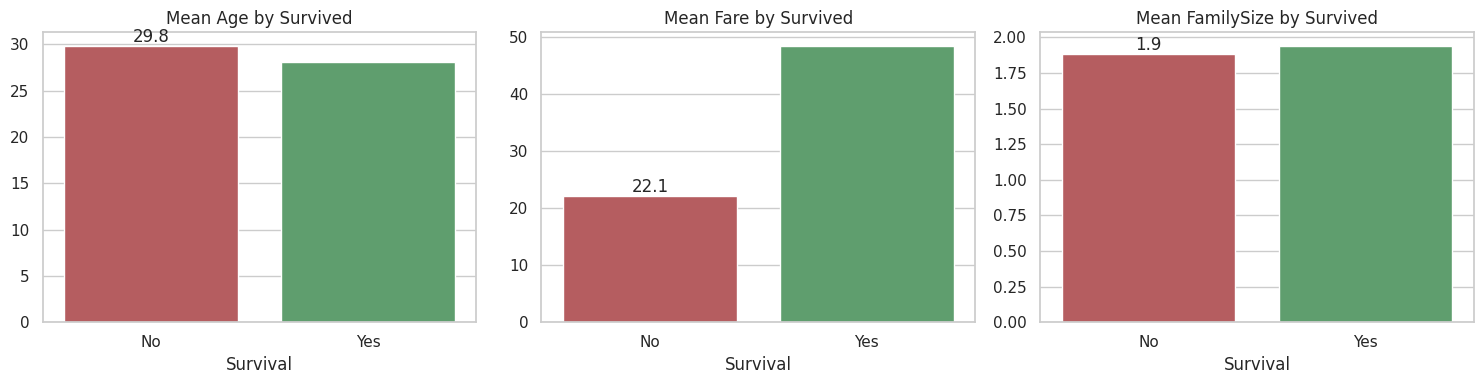

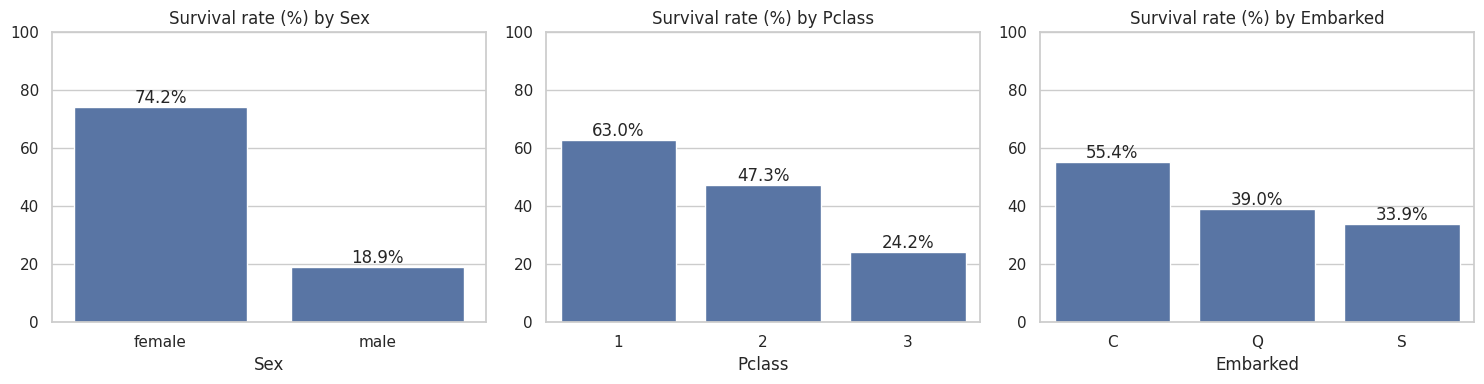

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Fare", "FamilySize"]):
    m = df.groupby("Survival")[col].mean().reindex(["No", "Yes"])
    sns.barplot(x=m.index, y=m.values, palette=["#c44e52", "#55a868"], ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f"); ax.set_title(f"Mean {col} by Survived")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    r = df.groupby(col)["Survived"].mean() * 100
    sns.barplot(x=r.index, y=r.values, ax=ax); ax.set_ylim(0, 100)
    ax.bar_label(ax.containers[0], fmt="%.1f%%"); ax.set_title(f"Survival rate (%) by {col}")
plt.tight_layout(); plt.show()

**Interpretation.** Survivors paid on average more than twice the fare of non-survivors (48.4 vs 22.1), so Fare looks useful. Mean age is almost the same (28.1 vs 29.8) and family size is nearly equal (1.9 each), so these two are weak on their own. Survival rate by group: females 74.2% vs males 18.9%; class 1 63.0%, class 2 47.3%, class 3 24.2%; Cherbourg 55.4%, Queenstown 39.0%, Southampton 33.7%. **Sex and Pclass are the strongest early-warning features.**

## Step 8: Feature vs Feature, Scatter Plot

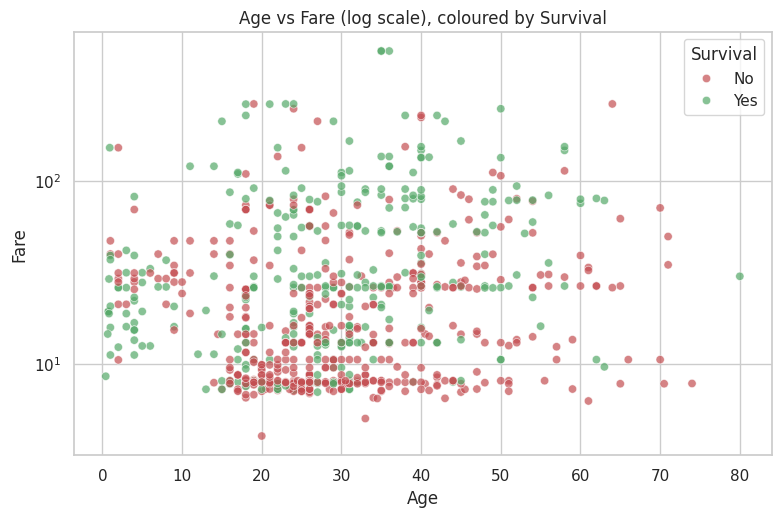

Correlation Age-Fare: 0.12


In [100]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survival", hue_order=["No", "Yes"],
                palette=["#c44e52", "#55a868"], alpha=0.7)
plt.yscale("log"); plt.title("Age vs Fare (log scale), coloured by Survival"); plt.show()
print("Correlation Age-Fare:", round(df["Age"].corr(df["Fare"]), 2))

**Interpretation.** There is no clear pattern between Age and Fare (correlation about 0.1), so older passengers did not systematically pay more. The target groups overlap heavily, but green points (survivors) become more common as fare increases, and the youngest passengers on the left are mostly green. Age and Fare alone do not separate the classes.

## Step 9: Many Feature Relationships, Heatmap

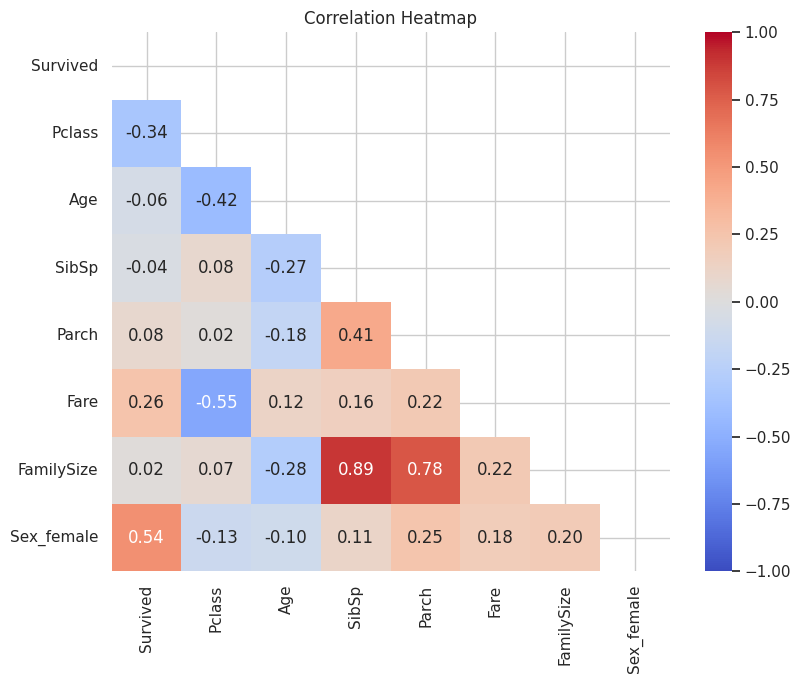

Sex_female    0.54
Pclass       -0.34
Fare          0.26
Parch         0.08
Age          -0.06
SibSp        -0.04
FamilySize    0.02
Name: Survived, dtype: float64


In [101]:
df["Sex_female"] = (df["Sex"] == "female").astype(int)
cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "Sex_female"]
corr = df[cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title("Correlation Heatmap"); plt.show()
print(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(2))

**Interpretation**

- **Strong positive:** SibSp–FamilySize (0.89) and Parch–FamilySize (0.78) are strong only because FamilySize is built from them. Sex_female–Survived (0.54) is the strongest link with the target.
- **Moderate negative:** Pclass–Fare (−0.55), Pclass–Age (−0.42) and Pclass–Survived (−0.34).
- **Moderate positive:** SibSp–Parch (0.41) and Fare–Survived (0.26).
- **Weak (near 0):** Age (−0.06), SibSp (−0.04), Parch (0.08) and FamilySize (0.02) against Survived.

No raw feature pair above 0.7 means little multicollinearity, except FamilySize with its own parts.

## Step 10: Multiple Features Together

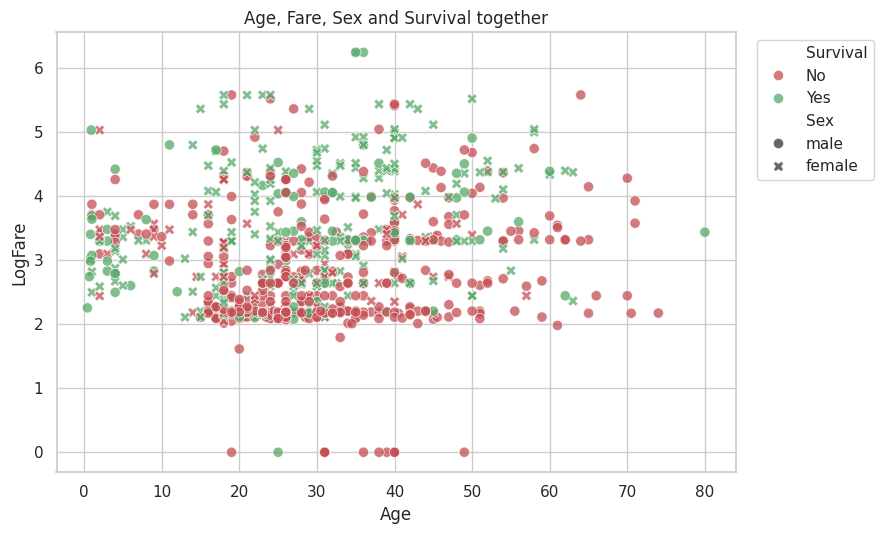

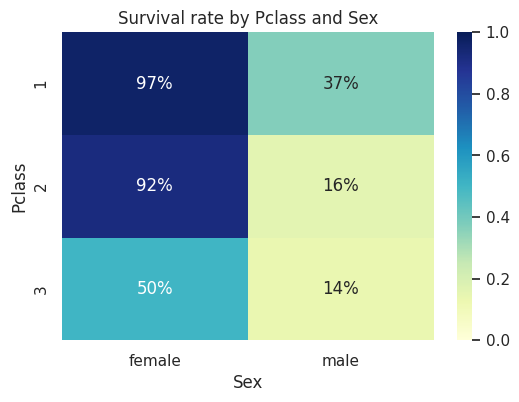

In [102]:
# (a) Age + Fare + Sex + Survival together
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="Age", y="LogFare", hue="Survival", style="Sex",
                hue_order=["No", "Yes"], palette=["#c44e52", "#55a868"], alpha=0.75, s=55)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("Age, Fare, Sex and Survival together"); plt.tight_layout(); plt.show()

# (b) Sex x Pclass survival rate
pt = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
plt.figure(figsize=(6, 4))
sns.heatmap(pt, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival rate by Pclass and Sex"); plt.show()

**Interpretation.** Taken together the features show clear groups that single plots hide. First- and second-class women survived at 97% and 92%, third-class women at 50%, while men survived at only 37% (class 1), 16% (class 2) and 14% (class 3). In the scatter, crosses (women) are mostly green and circles (men) mostly red at every fare level. Sex has the main effect and class changes it.

## Step 11: Trends, Patterns and Anomalies

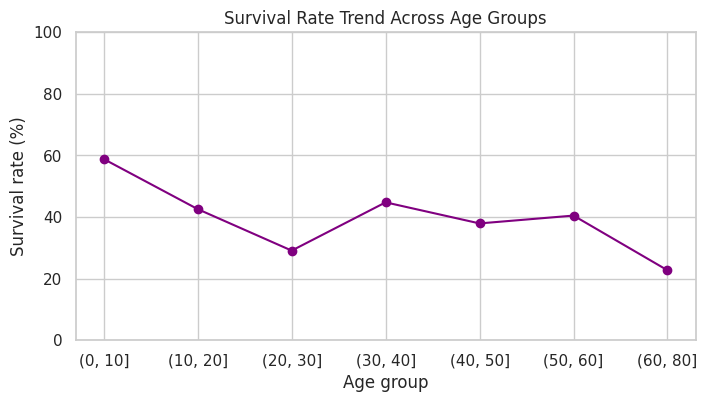

AgeBin
(0, 10]     58.8
(10, 20]    42.6
(20, 30]    29.1
(30, 40]    44.8
(40, 50]    37.9
(50, 60]    40.5
(60, 80]    22.7
Name: Survived, dtype: float64

First-class women who did NOT survive (unexpected):


,Name,Age,Fare
177,"Isham, Miss. Ann Elizabeth",50.0,28.7125
297,"Allison, Miss. Helen Loraine",2.0,151.5500
498,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",25.0,151.5500


Passengers with Fare = 0: 15
Top 3 fares: [512.33, 512.33, 512.33]


In [103]:
# Trend (line plot): survival rate across age groups
df["AgeBin"] = pd.cut(df["Age"], [0, 10, 20, 30, 40, 50, 60, 80])
trend = df.groupby("AgeBin", observed=True)["Survived"].mean() * 100
plt.figure(figsize=(8, 4))
plt.plot(trend.index.astype(str), trend.values, marker="o", color="purple")
plt.ylim(0, 100); plt.ylabel("Survival rate (%)"); plt.xlabel("Age group")
plt.title("Survival Rate Trend Across Age Groups"); plt.grid(True); plt.show()
print(trend.round(1))

# Anomalies
print("\nFirst-class women who did NOT survive (unexpected):")
display(df[(df.Pclass == 1) & (df.Sex == "female") & (df.Survived == 0)][["Name", "Age", "Fare"]])
print("Passengers with Fare = 0:", (df.Fare == 0).sum())
print("Top 3 fares:", df["Fare"].nlargest(3).round(2).tolist())

**Interpretation**

- **Trend:** survival is highest for children aged 0 to 10 (59%), drops to its lowest at 20 to 30 (29%), recovers to about 45% at 30 to 40, and falls again to 23% for passengers over 60. Children were given priority and the oldest were least likely to survive.
- **Anomalies:** only 3 first-class women died (a 97% survival group), including 2-year-old Helen Allison and her mother. 15 passengers have `Fare = 0` (all men, only 1 survived), which may be crew, guests or missing data. Three tickets cost the maximum 512.33 and all three survived.

## From EDA to Modeling Decisions (Final Findings)

1. **Sex, Pclass and Fare** are the strongest early-warning indicators of survival. Keep them.
2. **Age, SibSp and Parch** are weak alone (|r| < 0.1), but Age matters for children and FamilySize helps in groups, so use group versions (age bands, FamilySize) rather than raw columns.
3. **Features interact** (Sex × Pclass), so tree-based models or interaction terms are a good fit.
4. **The target is somewhat imbalanced** (61.6% / 38.4%), so use a stratified split and report precision, recall and F1, not just accuracy.
5. **Fare is heavily skewed** (4.8), so use `LogFare`. The 116 outliers are real tickets and should not be deleted. The 15 zero-fare records need a separate check.
6. **Pclass and Fare overlap** (−0.55) and **FamilySize is built from SibSp and Parch** (0.89), so avoid feeding all of them into a linear model without care.

**3Cs reminder:** these are associations, not causes (Character), unusual cases were questioned rather than ignored (Courage), and each plot was matched to its question (Competence).